# Ridge Logistic Regression
Owner: Anupama Singh

Logistic Regression with an L2 (Ridge) penalty, tuned. The counterpart to the Lasso (L1) notebook: L2 shrinks every coefficient toward zero but keeps all features, while L1 can set coefficients to exactly zero. The plain Logistic Regression notebook also uses L2, but with a fixed `C=1`; here `C` is tuned.

## 1. Setup and data
Same data as the paper and as the rest of the team: 706 labeled students with no missing values, the paper's 16 features, two targets. The folds are identical to Megha's Random Forest and XGBoost notebooks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, mean_absolute_error
from sklearn.linear_model import LogisticRegression
# Data: local copy in data/ if present, otherwise download from the ECRI repository
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL

# Outputs: the repo's results/ folder when run locally, ./results in Colab
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)

# The paper's 16 features (Table 3) and the two Woodcock targets
FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS",
            "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
raw = pd.read_csv(f"{src}/ECRIRawData.csv", low_memory=False)

# Spring scores are used ONLY to compute the gain (regression target), never as features
spring = raw[raw["Time"] == 2.0].set_index("StuID")[list(TARGETS.values())].add_suffix("_spring")

# Labeled students with no missing feature values, as in the paper (706 students)
data = (df[df["RMwidRS_target"].notna()]
        .dropna(subset=FEATURES)
        .join(spring, on="StuID")
        .reset_index(drop=True))
for score in TARGETS.values():
    data[f"{score}_gain"] = data[f"{score}_spring"] - data[score]

X = data[FEATURES]
print(f"Students: {len(data)} | Schools: {data['SchlID'].nunique()} | Features: {len(FEATURES)}")

Students: 706 | Schools: 42 | Features: 16


## 2. The model
- Features are standardized inside each training fold.
- `C` sets the penalty strength: a **smaller** `C` means a **stronger** penalty and smaller coefficients.
- `C` is **tuned inside each training fold** with an inner 4-fold cross-validation (best ROC AUC). The test fold is never used for this choice.

In [2]:
import warnings
# Newer scikit-learn versions (1.8+) announce renamed settings; the code below works on all versions
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")
warnings.filterwarnings("ignore", message="Inconsistent values", category=UserWarning)

MODEL_NAME = "Ridge Logistic Regression"
KIND = "classifier"
SETTINGS = {"C=0.001": 0.001, "C=0.01": 0.01, "C=0.1": 0.1, "C=1": 1.0, "C=10": 10.0}


def build_model(name):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(penalty="l2", C=SETTINGS[name], max_iter=2000))


def pick_setting(X_train, y_train, groups_train):
    # Inner 4-fold grouped CV on the training folds only (best ROC AUC); the test fold is never used
    scores = {name: cross_val_score(build_model(name), X_train, y_train, cv=GroupKFold(4),
                                    groups=groups_train, scoring="roc_auc").mean()
              for name in SETTINGS}
    return max(scores, key=scores.get)

## 3. 5-fold cross-validation
- **School split (main):** `GroupKFold(5)` on `SchlID`. Every school sits in exactly one test fold, so each student is scored by a model that never saw their school.
- **Student split:** `GroupKFold(5)` on `StuID`, so a school can appear in both training and test.

Each round trains on 4 folds (about 565 students) and predicts the 5th (about 141). The prediction for every student is saved so the evaluation notebook can compute all metrics and curves.

In [3]:
SPLITS = {"school": "SchlID", "student": "StuID"}


def cross_validate(score, split):
    """5-fold grouped cross-validation. Returns one row per student with the out-of-fold prediction."""
    groups = data[SPLITS[split]]
    y = data[f"{score}_target"] if KIND == "classifier" else data[f"{score}_gain"]
    rows = []
    for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
        setting = pick_setting(X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx])
        model = build_model(setting).fit(X.iloc[train_idx], y.iloc[train_idx])
        test = data.iloc[test_idx]
        prediction = model.predict_proba(test[FEATURES])[:, 1]    # probability of label 1
        pred_label = (prediction >= 0.5).astype(int)
        rows.append(pd.DataFrame({
            "split": split, "target": score, "model": MODEL_NAME, "fold": fold,
            "StuID": test["StuID"].values, "SchlID": test["SchlID"].values, "setting": setting,
            "true_label": test[f"{score}_target"].astype(int).values,
            "true_gain": test[f"{score}_gain"].values,
            "score": prediction,          # probability of label 1
            "pred_label": pred_label,
        }))
    return pd.concat(rows, ignore_index=True)


predictions = pd.concat([cross_validate(score, split)
                         for split in SPLITS for score in TARGETS.values()], ignore_index=True)
print("Predictions:", len(predictions), "rows (706 students x 2 targets x 2 splits)")

Predictions: 2824 rows (706 students x 2 targets x 2 splits)


## 4. Quick summary
Mean over the 5 folds. The full set of metrics and curves (precision, recall, ROC and PR curves, squared error) is in `anupama_baseline_evaluation.ipynb`.

In [4]:
rows = []
for (split, score, fold), g in predictions.groupby(["split", "target", "fold"]):
    row = {"split": split, "target": score, "fold": fold,
           "ROC AUC": roc_auc_score(g["true_label"], g["score"]),
           "PR-AUC": average_precision_score(g["true_label"], g["score"]),
           "Accuracy": accuracy_score(g["true_label"], g["pred_label"])}
    rows.append(row)
fold_results = pd.DataFrame(rows)

summary = (fold_results.drop(columns="fold").groupby(["split", "target"])
           .agg(["mean", "std"]).round(3)
           .rename(index={v: k for k, v in TARGETS.items()}, level=1))
summary

ROC AUC        PR-AUC        Accuracy       
                               mean    std   mean    std     mean    std
split   target                                                          
school  Word Attack           0.615  0.040  0.693  0.078    0.613  0.064
        Word Identification   0.671  0.057  0.683  0.048    0.637  0.055
student Word Attack           0.632  0.032  0.706  0.041    0.622  0.045
        Word Identification   0.667  0.071  0.689  0.091    0.637  0.066

## Setting chosen in each fold
Picked by the inner cross-validation inside each training fold.

In [5]:
(predictions.groupby(["split", "target", "fold"])["setting"].first()
 .unstack("fold").rename(index={v: k for k, v in TARGETS.items()}, level=1))

fold                             1      2     3      4     5
split   target                                              
school  Word Attack            C=1   C=10  C=10   C=10  C=10
        Word Identification    C=1   C=10   C=1  C=0.1   C=1
student Word Attack           C=10  C=0.1  C=10   C=10   C=1
        Word Identification  C=0.1  C=0.1  C=10   C=10   C=1

## 6. How L2 shrinks the coefficients (Word Identification)
Each line is one feature's coefficient as `C` changes, fitted on all 706 students. Moving left (smaller `C`, stronger penalty), every coefficient shrinks toward zero together, but none is removed. Compare with the Lasso notebook, where weak features drop to exactly zero.

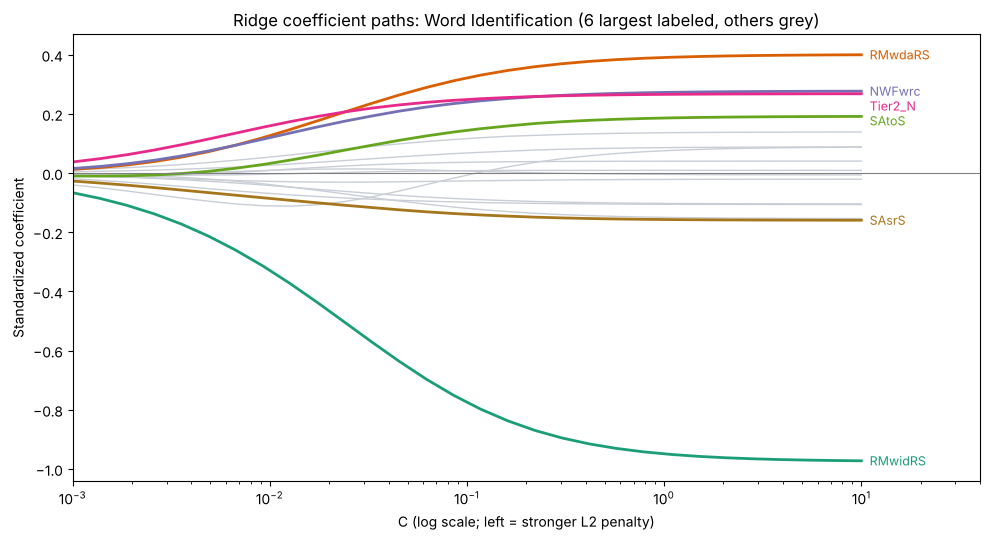

In [6]:
c_values = np.logspace(-3, 1, 30)
paths = np.array([build_model("C=1").set_params(logisticregression__C=c)
                  .fit(X, data["RMwidRS_target"])[-1].coef_[0] for c in c_values])
top = list(np.argsort(-np.abs(paths[-1]))[:6])
colors = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#a6761d"]
fig, ax = plt.subplots(figsize=(10, 5.5))
for j in range(len(FEATURES)):
    if j not in top:
        ax.plot(c_values, paths[:, j], color="#c9ced6", linewidth=1)
# Spread the end labels so lines that finish at the same height do not overlap
ends = sorted(((paths[-1, j], j) for j in top), reverse=True)
label_y, last = {}, None
for y, j in ends:
    y = y if last is None else min(y, last - 0.05)
    label_y[j], last = y, y
for color, j in zip(colors, top):
    ax.plot(c_values, paths[:, j], color=color, linewidth=2)
    ax.annotate(FEATURES[j], (c_values[-1], label_y[j]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=color)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlim(c_values[0], c_values[-1] * 4)
ax.set_xlabel("C (log scale; left = stronger L2 penalty)")
ax.set_ylabel("Standardized coefficient")
ax.set_title("Ridge coefficient paths: Word Identification (6 largest labeled, others grey)")
plt.tight_layout()
plt.savefig(RESULTS / "ridge_logistic_regression_coefficient_paths.png", dpi=150)
plt.show()

## 7. L2 (Ridge) vs L1 (Lasso) coefficients
Fitted on all 706 students with the `C` chosen most often in the school split for each model. Lasso sets some coefficients to exactly zero; Ridge keeps every feature.

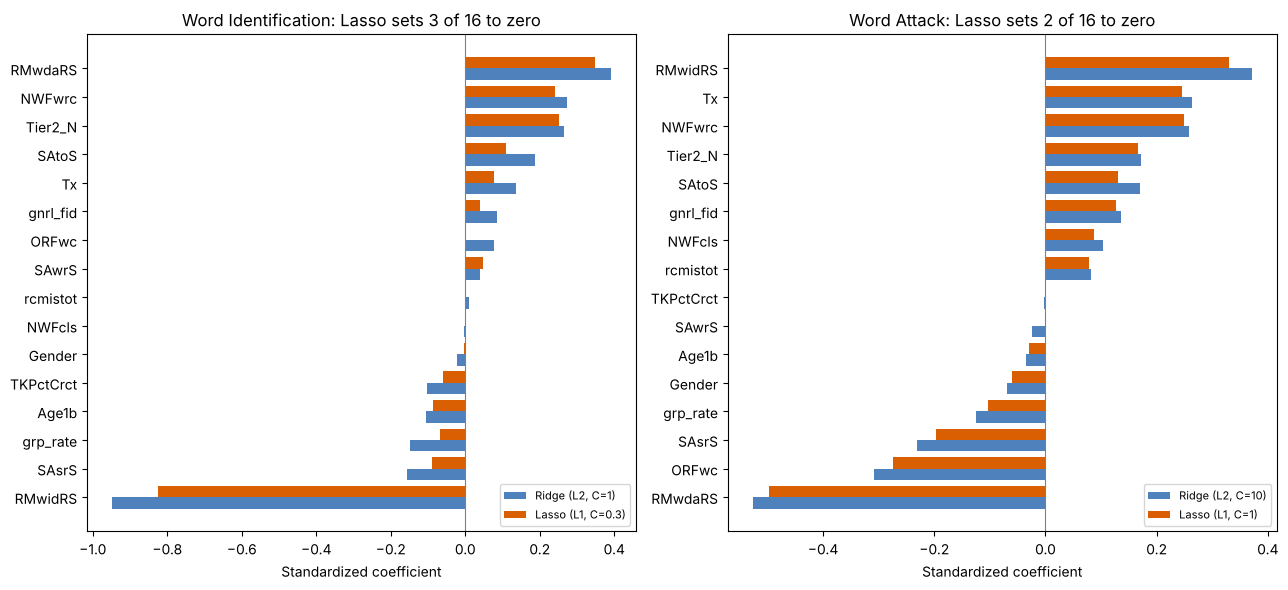

In [7]:
LASSO_C = {"C=0.01": 0.01, "C=0.03": 0.03, "C=0.1": 0.1, "C=0.3": 0.3, "C=1": 1.0}
school = predictions[predictions["split"] == "school"]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (target_name, score) in zip(axes, TARGETS.items()):
    chosen = school[school["target"] == score].groupby("fold")["setting"].first().mode()[0]
    ridge = build_model(chosen).fit(X, data[f"{score}_target"])[-1].coef_[0]
    try:
        lasso_pred = pd.read_csv(RESULTS / "lasso_logistic_regression_cv_predictions.csv")
        lasso_c = (lasso_pred[(lasso_pred["split"] == "school") & (lasso_pred["target"] == score)]
                   .groupby("fold")["setting"].first().mode()[0])
    except FileNotFoundError:
        lasso_c = "C=0.3"
    lasso = make_pipeline(StandardScaler(), LogisticRegression(
        penalty="l1", solver="liblinear", C=LASSO_C[lasso_c], random_state=0)).fit(
        X, data[f"{score}_target"])[-1].coef_[0]
    order = np.argsort(ridge)
    ypos = np.arange(len(FEATURES))
    ax.barh(ypos - 0.2, ridge[order], height=0.4, color="#4f81bd", label=f"Ridge (L2, {chosen})")
    ax.barh(ypos + 0.2, lasso[order], height=0.4, color="#d95f02", label=f"Lasso (L1, {lasso_c})")
    ax.set_yticks(ypos, [FEATURES[i] for i in order])
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(f"{target_name}: Lasso sets {int((lasso == 0).sum())} of {len(FEATURES)} to zero")
    ax.set_xlabel("Standardized coefficient")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS / "ridge_vs_lasso_coefficients.png", dpi=150)
plt.show()

## Save the results

In [8]:
predictions.to_csv(RESULTS / "ridge_logistic_regression_cv_predictions.csv", index=False)
fold_results.to_csv(RESULTS / "ridge_logistic_regression_cv_fold_results.csv", index=False)
print(f"Saved ridge_logistic_regression_cv_predictions.csv and ridge_logistic_regression_cv_fold_results.csv to {RESULTS}/")

Saved ridge_logistic_regression_cv_predictions.csv and ridge_logistic_regression_cv_fold_results.csv to ../results/
